In [32]:
using Fluidum
using PyPlot
# Plotting related imports
include("Libs/plotter.jl");
directory = "Plots/Paper/Test2/";
save_plots = true;

In [33]:
# kernel_folder = "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_Importance_Study/kernels_pce_276_reference/";
kernel_folder = "/Kernels_Rafet/";
PCE = true

# save_all_particles(kernel_folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
# save_all_particles(kernel_folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)
dic = dictionary_pions(kernel_folder);

LoadError: ArgumentError: Cannot open '/Kernels_Rafet/particles.data': not a file

In [21]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE276;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (0.91477, 20);
norm = 34.487;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent276 = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "Rossana.txt"));

list = readresonancelist();

┌ Warning: centrality chosen is not a multiple of the bin size. Using 0-4 instead
└ @ Fluidum ~/.julia/dev/Fluidum.jl/src/fluidevo/map_profile.jl:29


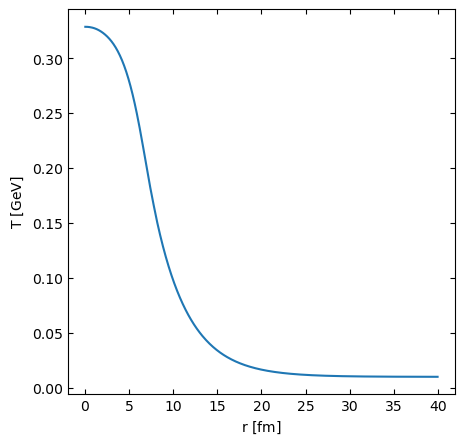

In [22]:
fields = Fluidum.initialize_fields(ent276, 0, 5; grid_params, initial_params);
#eos = Heavy_Quark();
eos = FluiduMEoS();

plot_initial_field(fields; save=save_plots, path=directory*"initial_field_Azyhydro_pTvn.png");

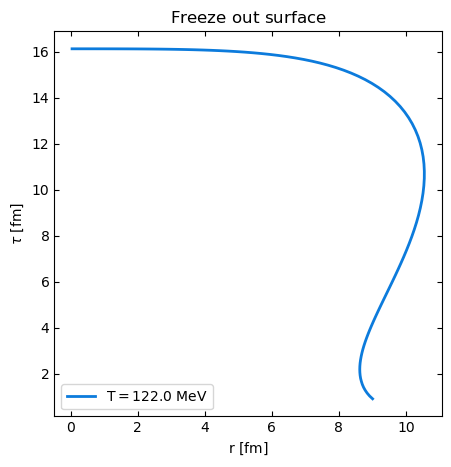

In [23]:
viscosity = QGPViscosity(0.54437,0.2); #or, ZeroViscosity();
#viscosity = QGPViscosity(2.0874, 0.2)
bulk = SimpleBulkViscosity(0.017963,15.0); #or, ZeroBulkViscosity();

diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!_Tscale, params, fields.initial_field, tspan; Tfo = 0.1215);
plot_fo_surface(fo;save=save_plots);

In [24]:
# phi = fields.initial_field
# dpt = Fluidum.pressure_derivative(phi[1],Val(1),params.eos) #entropy

# temperature_list = range(0, 1, 100)
# etas = []
# const fmGeV= 1/0.1973261 
# const invfmGeV= 1/fmGeV

# for T in temperature_list
#     eta = Fluidum.viscosity_Tscale(T,dpt, params.shear) / (dpt*invfmGeV)
#     push!(etas, eta)
# end

# etaMin = Fluidum.viscosity_Tscale(0.145,dpt, params.shear) / (dpt*invfmGeV)

# fig, ax = subplots(1,1, figsize=(5,5))
# ax.plot(temperature_list, etas)
# ax.set_xlabel("Temperature [GeV]")
# ax.set_ylabel(L"$\eta \, / \, s$")
# ax.set_title("Temperature Dependence of Viscosity")
# ax.text(0.5, 0.5, "Minimum eta/s:  "*string(round(etaMin, digits=5)), transform=ax.transAxes)
# #ax.set_yscale("log")
# ax.set_ylim(0, 1)
# ax.tick_params(which="both", direction="in", top=true, right=true)
# fig.show()

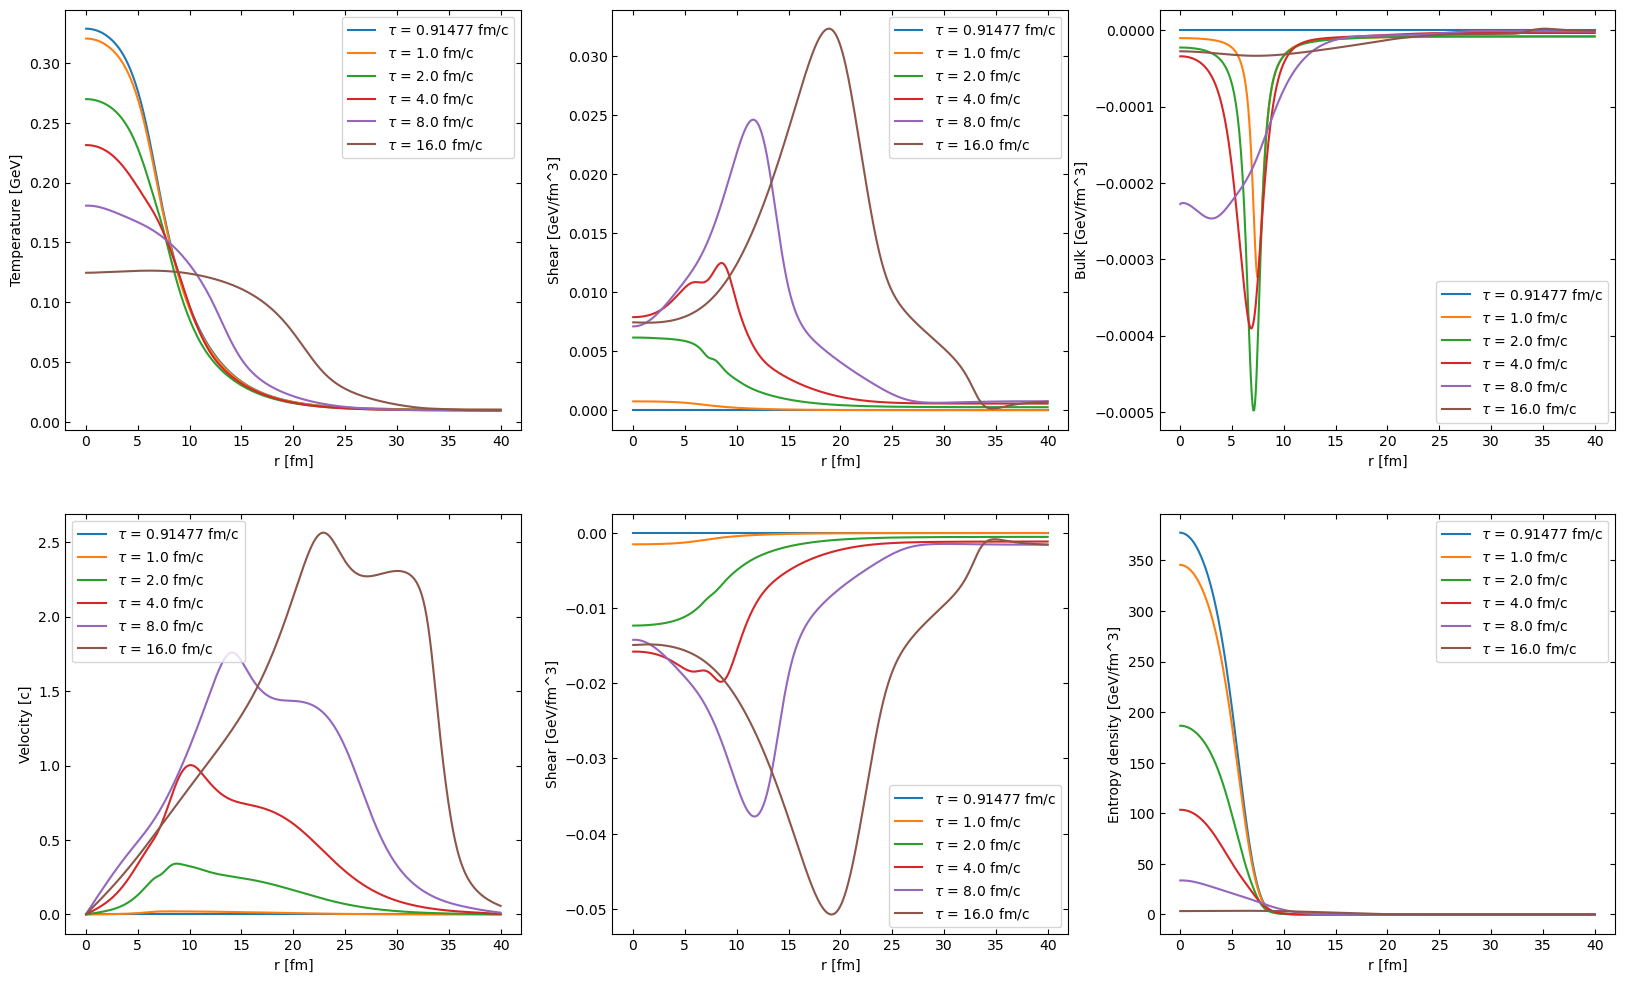

In [25]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [tspan[1], 1.0, 2.0, 4.0, 8.0, 16.0]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [26]:
include("Libs/data_lib.jl")

extraction_end_pion = 41; #number of data points to extract
extraction_end_proton = 34; #number of data points to extract
extraction_end_kaon = 36; #number of data points to extract
filename_pion = "ExperimentalData/HEPData-ins1222333-v1-Table_1.csv"
filename_proton = "ExperimentalData/HEPData-ins1222333-v1-Table_21.csv"
filename_kaon = "ExperimentalData/HEPData-ins1222333-v1-Table_11.csv"

data_pion = get_data(filename_pion, extraction_end_pion);
data_proton = get_data(filename_proton, extraction_end_proton);
data_kaon = get_data(filename_kaon, extraction_end_kaon);

mult_pion_data = calculate_yield(data_pion);
mult_proton_data = calculate_yield(data_proton);
mult_kaon_data = calculate_yield(data_kaon);

mult_pion_data_excess = calculate_yield(data_pion; excess=true);

In [27]:
include("Libs/results_lib.jl");

use_3d_kernel = false

results_pion = get_results(fo, dic.pion, params, data_pion.pt; interpolate_3d=use_3d_kernel);
# results_proton = get_results(fo, dic.proton, params, data_proton.pt; interpolate_3d=use_3d_kernel);
# results_kaon = get_results(fo, dic.kaon, params, data_kaon.pt; interpolate_3d=use_3d_kernel);

Total uncertainties: ([210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682773, 27.81150840928985, 21.311499243366246, 16.710774967068403, 9.912618221237011, 7.810249675906654, 6.711929677819934, 5.61426753904728, 4.601141162798638, 3.9706044879841658, 3.3309608223454084, 2.9091063920042526, 2.4399385238157127, 1.9701776569639602, 1.5546382215808283, 1.134416149391395, 0.8927485648266258, 0.6519202405202649, 0.4758571214135604, 0.35483094566286066, 0.26704681237565825, 0.20032473636573195, 0.15119854496654392, 0.11672617529928753, 0.0902551937563706, 0.07085795650454507, 0.05481204247243483, 0.04556237482836029, 0.03600472191254919, 0.029080061898145954, 0.02411057859114957, 0.01923460423299632, 0.01603277892319357, 0.013566502865514016], [210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682

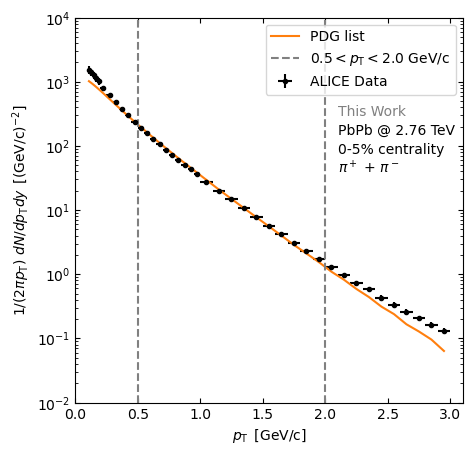

In [28]:
plot_spectra(results_pion, data_pion, mult_pion_data; save=save_plots)
# plot_spectra(results_proton, data_proton, mult_proton_data; save=save_plots)
# plot_spectra(results_kaon, data_kaon, mult_kaon_data; save=save_plots)
# excess, err_exp, err_th = calculate_excess(results_pion, mult_pion_data_excess);
# println("Pion excess: ", excess, " ± ", err_exp, " (exp) ± ", err_th, " (theo)");

mult_reference = results_pion.multiplicity_total_reference
println("Reference multiplicity (0.5 - 2.0 GeV/c): ", mult_reference[1], " +- ", mult_reference[2])

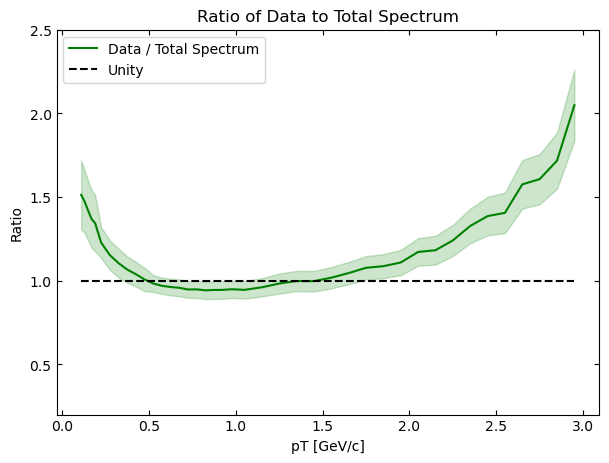

In [29]:
plot_ratio(results_pion, data_pion; save = save_plots)